# Vecka 4 — Filterdesign: FIR och IIR

**Syfte:** förstå hur ett digitalt filter ändrar en signals frekvensinnehåll, designa ett FIR- och ett IIR-lågpassfilter, jämföra dem och använda ett bandpassfilter för att rensa en ljudsignal.

Notebooken hör ihop med `docs/vecka_04_teori.md` och `R/vecka_04_filter.R`. Samma samplingsfrekvens som tidigare veckor:

| Parameter | Värde |
|---|---|
| Samplingsfrekvens | 16 000 Hz, 1 s |
| Testsignal | 440 Hz (0,5) + brum 50 Hz (0,3) + störton 6 000 Hz (0,2) + vitt brus (σ = 0,05, seed 42) |
| FIR-lågpass | fönstermetoden, 101 koefficienter, Hamming, gräns 1 000 Hz |
| IIR-lågpass | Butterworth ordning 4, gräns 1 000 Hz |
| Bandpass (tal) | Butterworth ordning 4, 300–3 400 Hz, nollfas (`sosfiltfilt`) |

Alla signaler är syntetiska. Kör cellerna uppifrån och ned (*Restart & Run All*).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sg
from scipy.io import wavfile
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

FS = 16000
t = np.arange(FS) / FS
rng = np.random.default_rng(42)

# Komponenterna hålls separata så att vi kan mäta exakt vad filtret gör med var och en
ren_440 = 0.5 * np.sin(2 * np.pi * 440 * t)      # önskad signal
brum_50 = 0.3 * np.sin(2 * np.pi * 50 * t)       # nätbrum
stor_6000 = 0.2 * np.sin(2 * np.pi * 6000 * t)   # högfrekvent störning
brus = 0.05 * rng.standard_normal(FS)            # vitt brus
mix = ren_440 + brum_50 + stor_6000 + brus

def snr_db(onskad, total, kant=int(0.1 * FS)):
    # SNR mitt i signalen (kanterna utesluts p.g.a. filtrens insvängning)
    rest = total - onskad
    return 10 * np.log10(np.mean(onskad[kant:-kant]**2) / np.mean(rest[kant:-kant]**2))

def svar_db(b, a, frekvenser):
    # Amplitudsvar |H(f)| i dB vid givna frekvenser
    _, H = sg.freqz(b, a, worN=np.atleast_1d(frekvenser), fs=FS)
    return 20 * np.log10(np.abs(H))

def spara_wav(namn, x):
    skala = 0.99 / np.max(np.abs(x))
    wavfile.write(DATA_DIR / namn, FS, np.round(x * skala * 32767).astype(np.int16))

spara_wav("vecka_04_mix.wav", mix)
print(f"SNR före filtrering: {snr_db(ren_440, mix):.2f} dB")
print("Sparad:", (DATA_DIR / "vecka_04_mix.wav").relative_to(ROOT).as_posix())

SNR före filtrering: 2.66 dB
Sparad: data/vecka_04_mix.wav


## 1. Differensekvation och frekvenssvar

Ett digitalt filter beräknar varje utsampel från nuvarande och tidigare insampel (och, för IIR, tidigare utsampel):

$$y[n] = \sum_{k=0}^{M} b_k\,x[n-k] \;-\; \sum_{k=1}^{N} a_k\,y[n-k]$$

Det enklaste exemplet är ett **glidande medelvärde** av M = 5 sampel, där alla b_k = 1/5. Dess frekvenssvar har nollställen vid multiplar av fs/M = 3 200 Hz:

$$|H(f)| = \left|\frac{\sin(\pi f M / f_s)}{M \sin(\pi f / f_s)}\right|$$

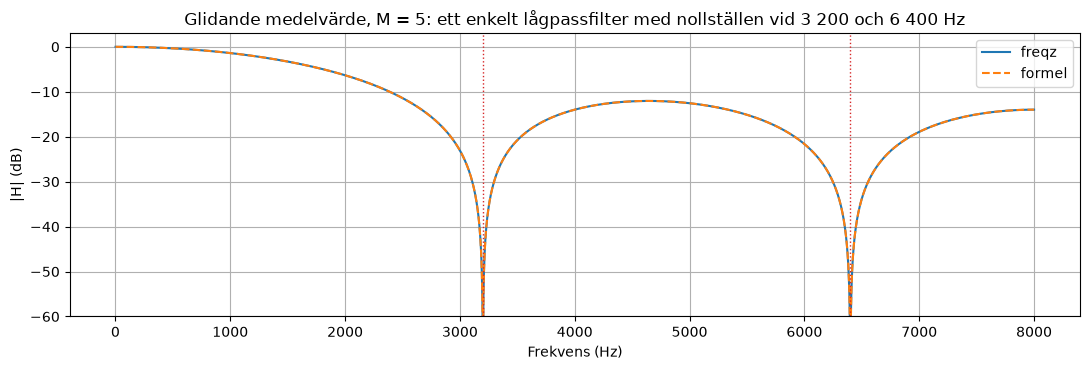

,Frekvens (Hz),|H|
0,0,1.0000
1,1000,0.8524
2,3200,0.0000
3,6400,0.0000


In [2]:
M = 5
b_mv = np.ones(M) / M
f = np.linspace(1, FS / 2, 4000)
uppmatt = svar_db(b_mv, 1, f)
formel = 20 * np.log10(np.abs(np.sin(np.pi * f * M / FS) / (M * np.sin(np.pi * f / FS))) + 1e-12)
assert np.allclose(uppmatt[uppmatt > -80], formel[uppmatt > -80], atol=1e-6)

plt.figure(figsize=(11, 3.8))
plt.plot(f, uppmatt, label="freqz")
plt.plot(f, formel, "--", label="formel")
for nolla in [3200, 6400]:
    plt.axvline(nolla, color="tab:red", ls=":", lw=1)
plt.ylim(-60, 3)
plt.title("Glidande medelvärde, M = 5: ett enkelt lågpassfilter med nollställen vid 3 200 och 6 400 Hz")
plt.xlabel("Frekvens (Hz)")
plt.ylabel("|H| (dB)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "vecka_04_medelvarde.png", dpi=120)
plt.show()

pd.DataFrame({"Frekvens (Hz)": [0, 1000, 3200, 6400],
              "|H|": np.round(np.abs(sg.freqz(b_mv, 1, worN=[0, 1000, 3200, 6400], fs=FS)[1]), 4)})

## 2. FIR-lågpass med fönstermetoden

Ett idealt lågpassfilter med gräns f_c har impulssvaret sinc, som är oändligt långt. Fönstermetoden klipper sinc till N koefficienter och multiplicerar med ett fönster (Hamming), precis som i vecka 3:

$$h[n] = \underbrace{2\frac{f_c}{f_s}\,\operatorname{sinc}\!\left(2\frac{f_c}{f_s}\left(n - \tfrac{N-1}{2}\right)\right)}_{\text{ideal lågpass, förskjuten}} \cdot w_{\text{Hamming}}[n]$$

Koefficienterna är symmetriska, så filtret har **linjär fas**: alla frekvenser fördröjs lika mycket, (N − 1)/2 = 50 sampel = 3,125 ms.

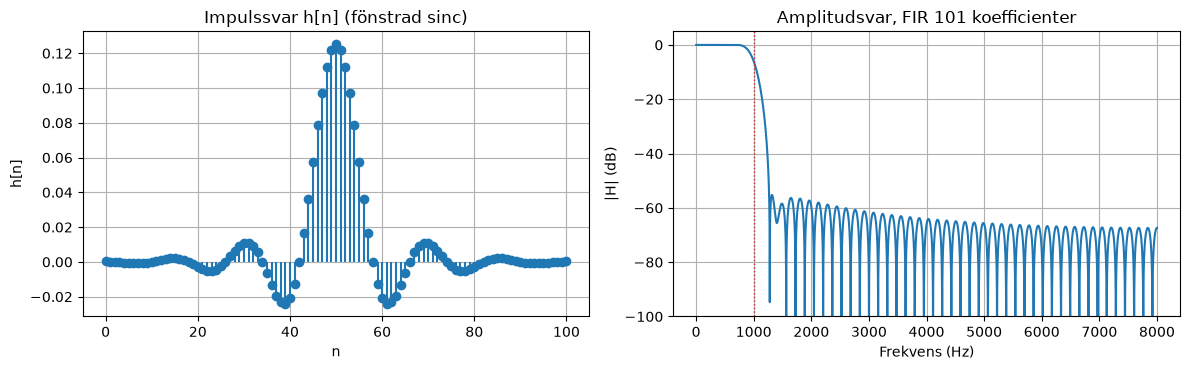

,Mått,Värde
0,Antal koefficienter,101
1,−3 dB vid (Hz),937.0
2,−6 dB vid (Hz),1001.0
3,Förstärkning 440 Hz (dB),0.015
4,Dämpning 2 000 Hz (dB),-59.6
5,Dämpning 6 000 Hz (dB),-76.1
6,Gruppfördröjning (sampel),"[50.0, 50.0, 50.0]"
7,Gruppfördröjning (ms),3.125


In [3]:
N_FIR = 101
h_fir = sg.firwin(N_FIR, 1000, fs=FS, window="hamming")
assert np.allclose(h_fir, h_fir[::-1])          # symmetrisk → linjär fas

f = np.linspace(1, FS / 2, 8000)
H_fir = svar_db(h_fir, 1, f)
_, gd_fir = sg.group_delay((h_fir, 1), w=[200, 440, 900], fs=FS)

fir_tabell = pd.DataFrame([
    ("Antal koefficienter", N_FIR),
    ("−3 dB vid (Hz)", round(float(f[np.argmax(H_fir < -3.0103)]), 1)),
    ("−6 dB vid (Hz)", round(float(f[np.argmax(H_fir < -6.0206)]), 1)),
    ("Förstärkning 440 Hz (dB)", round(float(svar_db(h_fir, 1, 440)[0]), 3)),
    ("Dämpning 2 000 Hz (dB)", round(float(svar_db(h_fir, 1, 2000)[0]), 1)),
    ("Dämpning 6 000 Hz (dB)", round(float(svar_db(h_fir, 1, 6000)[0]), 1)),
    ("Gruppfördröjning (sampel)", list(np.round(gd_fir, 2))),
    ("Gruppfördröjning (ms)", round(1000 * (N_FIR - 1) / 2 / FS, 3)),
], columns=["Mått", "Värde"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].stem(np.arange(N_FIR), h_fir, basefmt=" ")
axes[0].set(title="Impulssvar h[n] (fönstrad sinc)", xlabel="n", ylabel="h[n]")
axes[1].plot(f, H_fir)
axes[1].axvline(1000, color="tab:red", ls=":", lw=1)
axes[1].set(title="Amplitudsvar, FIR 101 koefficienter", xlabel="Frekvens (Hz)", ylabel="|H| (dB)", ylim=(-100, 5))
for ax in axes:
    ax.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "vecka_04_fir.png", dpi=120)
plt.show()
fir_tabell

Största skillnad mellan FIR-utsignal och 440 Hz fördröjd 50 sampel: 0.0009


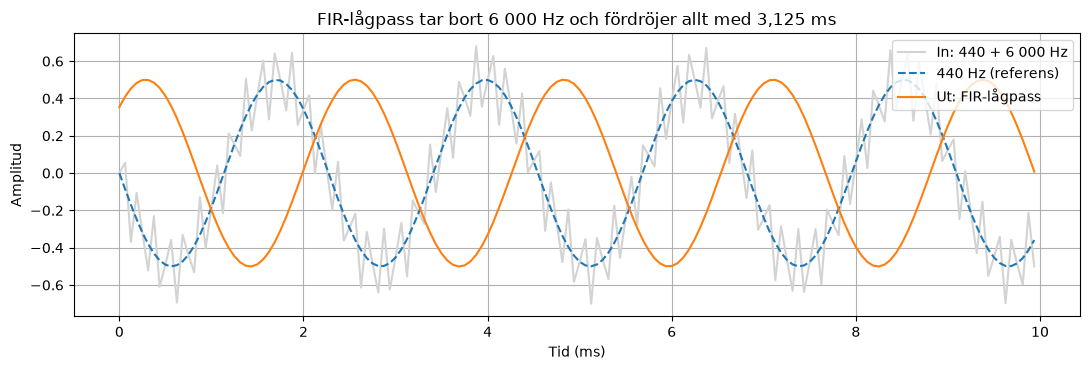

In [4]:
# Linjär fas i praktiken: utsignalen är 440 Hz-tonen fördröjd exakt 50 sampel
x_in = ren_440 + stor_6000
y_fir = sg.lfilter(h_fir, 1, x_in)
fordrojning = (N_FIR - 1) // 2
fel = np.max(np.abs(y_fir[fordrojning + 200:] - ren_440[200:-fordrojning]))
print(f"Största skillnad mellan FIR-utsignal och 440 Hz fördröjd {fordrojning} sampel: {fel:.4f}")

n_visa = int(0.01 * FS)
tid_ms = 1000 * np.arange(n_visa) / FS
plt.figure(figsize=(11, 3.8))
plt.plot(tid_ms, x_in[1000:1000 + n_visa], color="lightgray", label="In: 440 + 6 000 Hz")
plt.plot(tid_ms, ren_440[1000:1000 + n_visa], "--", label="440 Hz (referens)")
plt.plot(tid_ms, y_fir[1000:1000 + n_visa], label="Ut: FIR-lågpass")
plt.title("FIR-lågpass tar bort 6 000 Hz och fördröjer allt med 3,125 ms")
plt.xlabel("Tid (ms)")
plt.ylabel("Amplitud")
plt.legend(loc="upper right")
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "vecka_04_fir_fordrojning.png", dpi=120)
plt.show()

## 3. IIR-lågpass: Butterworth

Ett IIR-filter använder återkoppling (tidigare utsampel), så få koefficienter räcker för en brant övergång. Butterworth är **maximalt platt** i passbandet och har exakt −3 dB vid gränsfrekvensen:

$$|H(f)|^2 = \frac{1}{1 + (f/f_c)^{2n}}$$

(för det analoga prototypfiltret; den digitala versionen fås med bilinjär transform). Branthet: cirka 6·n dB per oktav. Filtret är stabilt om alla poler ligger **innanför enhetscirkeln**, |p| < 1. Fasen är inte linjär: gruppfördröjningen varierar med frekvensen och är störst nära gränsfrekvensen.

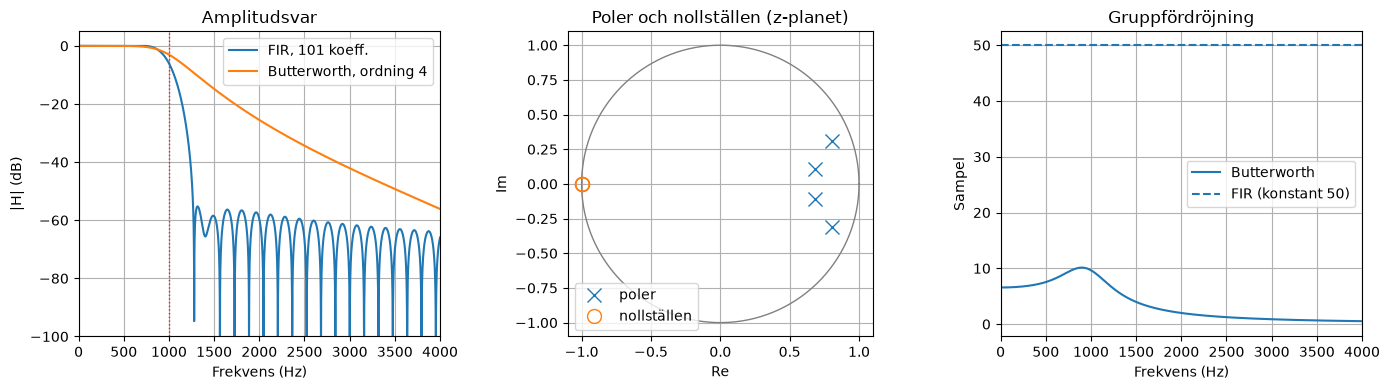

,Pol,|p|
0,0.8059+0.3084j,0.8629
1,0.8059-0.3084j,0.8629
2,0.6826+0.1082j,0.6911
3,0.6826-0.1082j,0.6911


In [5]:
ORDNING = 4
b_iir, a_iir = sg.butter(ORDNING, 1000, btype="low", fs=FS)
z, p, k = sg.tf2zpk(b_iir, a_iir)
assert np.all(np.abs(p) < 1)                    # stabilt

H_iir = svar_db(b_iir, a_iir, f)
f_gd = f[f < 7000]                              # undvik Nyquist, där filtret har nollställen
_, gd_iir = sg.group_delay((b_iir, a_iir), w=f_gd, fs=FS)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(f, H_fir, label="FIR, 101 koeff.")
axes[0].plot(f, H_iir, label="Butterworth, ordning 4")
axes[0].axvline(1000, color="tab:red", ls=":", lw=1)
axes[0].set(title="Amplitudsvar", xlabel="Frekvens (Hz)", ylabel="|H| (dB)", xlim=(0, 4000), ylim=(-100, 5))
axes[0].legend()
cirkel = np.exp(1j * np.linspace(0, 2 * np.pi, 400))
axes[1].plot(cirkel.real, cirkel.imag, color="gray", lw=1)
axes[1].plot(p.real, p.imag, "x", markersize=10, label="poler")
axes[1].plot(z.real, z.imag, "o", fillstyle="none", markersize=10, label="nollställen")
axes[1].set(title="Poler och nollställen (z-planet)", xlabel="Re", ylabel="Im", aspect="equal")
axes[1].legend(loc="lower left")
axes[2].plot(f_gd, gd_iir, label="Butterworth")
axes[2].axhline((N_FIR - 1) / 2, color="tab:blue", ls="--", label="FIR (konstant 50)")
axes[2].set(title="Gruppfördröjning", xlabel="Frekvens (Hz)", ylabel="Sampel", xlim=(0, 4000))
axes[2].legend()
for ax in axes:
    ax.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "vecka_04_iir.png", dpi=120)
plt.show()

pd.DataFrame({"Pol": np.round(p, 4), "|p|": np.round(np.abs(p), 4)})

In [6]:
# Ordningens betydelse: dubbel ordning ger dubbel dämpning (i dB)
rader = []
for n in [2, 4, 8]:
    b, a = sg.butter(n, 1000, fs=FS)
    rader.append({"Ordning": n,
                  "1 000 Hz (dB)": round(float(svar_db(b, a, 1000)[0]), 2),
                  "2 000 Hz (dB)": round(float(svar_db(b, a, 2000)[0]), 1),
                  "4 000 Hz (dB)": round(float(svar_db(b, a, 4000)[0]), 1)})
pd.DataFrame(rader)

,Ordning,1 000 Hz (dB),2 000 Hz (dB),4 000 Hz (dB)
0,2,-3.01,-13.0,-28.1
1,4,-3.01,-25.5,-56.1
2,8,-3.01,-51.0,-112.2


## 4. Jämförelse FIR och IIR

Båda filtren är lågpass med gräns 1 000 Hz, men de gör olika avvägningar.

In [7]:
jamforelse = pd.DataFrame([
    {"Egenskap": "Koefficienter (b + a)", "FIR": N_FIR, "IIR": len(b_iir) + len(a_iir)},
    {"Egenskap": "Multiplikationer per sampel", "FIR": N_FIR, "IIR": len(b_iir) + len(a_iir) - 1},
    {"Egenskap": "Nivå vid 1 000 Hz (dB)", "FIR": round(float(svar_db(h_fir, 1, 1000)[0]), 1), "IIR": round(float(svar_db(b_iir, a_iir, 1000)[0]), 1)},
    {"Egenskap": "Dämpning 2 000 Hz (dB)", "FIR": round(float(svar_db(h_fir, 1, 2000)[0]), 1), "IIR": round(float(svar_db(b_iir, a_iir, 2000)[0]), 1)},
    {"Egenskap": "Dämpning 6 000 Hz (dB)", "FIR": round(float(svar_db(h_fir, 1, 6000)[0]), 1), "IIR": round(float(svar_db(b_iir, a_iir, 6000)[0]), 1)},
    {"Egenskap": "Gruppfördröjning 440 Hz (sampel)", "FIR": 50.0, "IIR": round(float(sg.group_delay((b_iir, a_iir), w=[440], fs=FS)[1][0]), 2)},
    {"Egenskap": "Linjär fas", "FIR": "ja", "IIR": "nej"},
    {"Egenskap": "Alltid stabilt", "FIR": "ja", "IIR": "om |p| < 1"},
])
jamforelse

,Egenskap,FIR,IIR
0,Koefficienter (b + a),101,10
1,Multiplikationer per sampel,101,9
2,Nivå vid 1 000 Hz (dB),-6.0,-3.0
3,Dämpning 2 000 Hz (dB),-59.6,-25.5
4,Dämpning 6 000 Hz (dB),-76.1,-86.7
5,Gruppfördröjning 440 Hz (sampel),50.0,7.27
6,Linjär fas,ja,nej
7,Alltid stabilt,ja,om |p| < 1


## 5. Tillämpning: bandpass för tal (300–3 400 Hz)

Telefonbandet 300–3 400 Hz innehåller det mesta av talets begriplighet. Ett Butterworth-bandpass (ordning 4 per kant, alltså 8 totalt) tar bort brummet på 50 Hz, störtonen på 6 000 Hz och bruset utanför bandet.

`sosfiltfilt` filtrerar framåt och sedan bakåt: fasförskjutningarna tar ut varandra (**nollfas**), och dämpningen i dB fördubblas. Det fungerar bara offline, när hela signalen finns.

Eftersom filtret är linjärt kan varje komponent filtreras för sig, och SNR mäts exakt: önskad signal = filtrerad 440 Hz, störning = allt annat. Effekter mäts utan de första och sista 0,1 s, där filtret svänger in.

In [8]:
sos_bp = sg.butter(4, [300, 3400], btype="bandpass", fs=FS, output="sos")
filtrerad = sg.sosfiltfilt(sos_bp, mix)
spara_wav("vecka_04_filtrerad.wav", filtrerad)

KANT = int(0.1 * FS)   # hoppa över 0,1 s i varje ände, där filtret har insvängningseffekter

def rms_db(x):
    return 10 * np.log10(np.mean(x[KANT:-KANT]**2))

komponenter = {"440 Hz (önskad)": ren_440, "Brum 50 Hz": brum_50, "Störton 6 000 Hz": stor_6000, "Vitt brus": brus}
rader = []
for namn, komp in komponenter.items():
    ut = sg.sosfiltfilt(sos_bp, komp)
    rader.append({"Komponent": namn, "Effekt före (dB)": round(rms_db(komp), 1),
                  "Effekt efter (dB)": round(rms_db(ut), 1),
                  "Ändring (dB)": round(rms_db(ut) - rms_db(komp), 1)})
komponent_tabell = pd.DataFrame(rader)

snr_fore = snr_db(ren_440, mix)
snr_efter = snr_db(sg.sosfiltfilt(sos_bp, ren_440), filtrerad)
print(f"SNR före: {snr_fore:.2f} dB | SNR efter: {snr_efter:.2f} dB | förbättring: {snr_efter - snr_fore:.1f} dB")
print(f"Förväntad brusminskning om bara bandbredden räknas: 10·log10(3100/8000) = {10 * np.log10(3100 / 8000):.1f} dB")
komponent_tabell

SNR före: 2.66 dB | SNR efter: 21.28 dB | förbättring: 18.6 dB
Förväntad brusminskning om bara bandbredden räknas: 10·log10(3100/8000) = -4.1 dB


,Komponent,Effekt före (dB),Effekt efter (dB),Ändring (dB)
0,440 Hz (önskad),-9.0,-9.2,-0.2
1,Brum 50 Hz,-13.5,-143.3,-129.8
2,Störton 6 000 Hz,-17.0,-99.6,-82.6
3,Vitt brus,-26.0,-30.5,-4.5


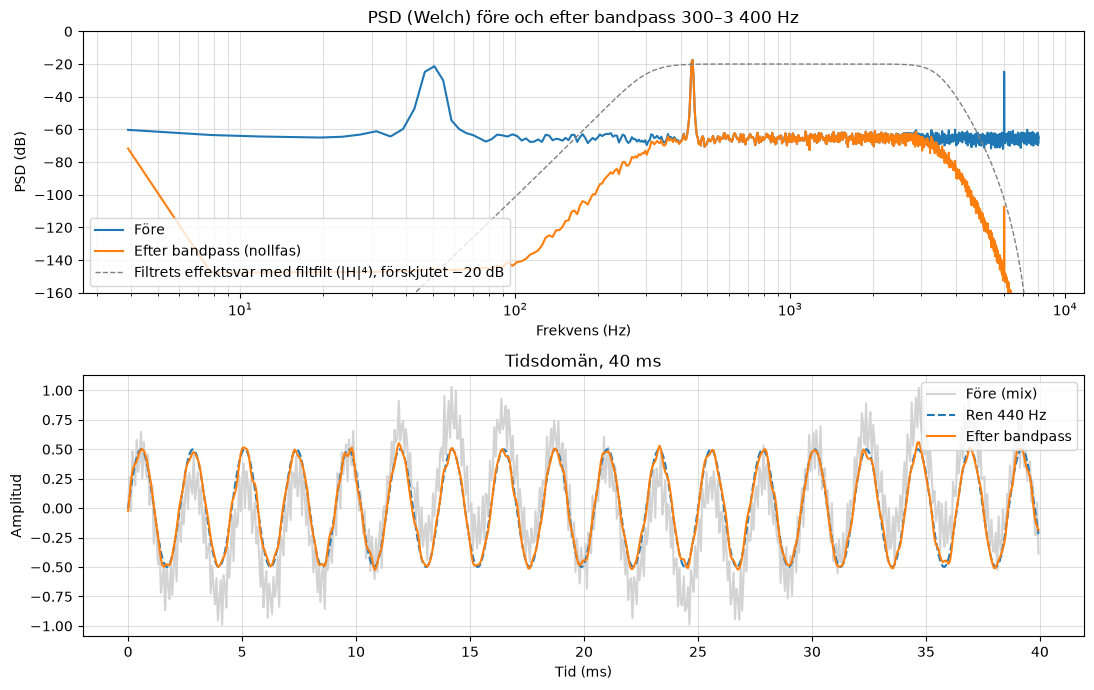

In [9]:
f_w, P_fore = sg.welch(mix, FS, nperseg=4096)
_, P_efter = sg.welch(filtrerad, FS, nperseg=4096)
_, H_bp = sg.sosfreqz(sos_bp, worN=f_w, fs=FS)

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].semilogx(f_w[1:], 10 * np.log10(P_fore[1:]), label="Före")
axes[0].semilogx(f_w[1:], 10 * np.log10(P_efter[1:] + 1e-20), label="Efter bandpass (nollfas)")
axes[0].semilogx(f_w[1:], 40 * np.log10(np.abs(H_bp[1:]) + 1e-20) - 20, color="gray", ls="--", lw=1, label="Filtrets effektsvar med filtfilt (|H|⁴), förskjutet −20 dB")
axes[0].set(title="PSD (Welch) före och efter bandpass 300–3 400 Hz", xlabel="Frekvens (Hz)", ylabel="PSD (dB)", ylim=(-160, 0))
axes[0].legend(loc="lower left")
n_visa = int(0.04 * FS)
tid_ms = 1000 * np.arange(n_visa) / FS
axes[1].plot(tid_ms, mix[4000:4000 + n_visa], color="lightgray", label="Före (mix)")
axes[1].plot(tid_ms, ren_440[4000:4000 + n_visa], "--", label="Ren 440 Hz")
axes[1].plot(tid_ms, filtrerad[4000:4000 + n_visa], label="Efter bandpass")
axes[1].set(title="Tidsdomän, 40 ms", xlabel="Tid (ms)", ylabel="Amplitud")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(True, which="both", alpha=0.4)
plt.tight_layout()
plt.savefig(FIG_DIR / "vecka_04_bandpass.png", dpi=120)
plt.show()

## 6. Slutsatser

- **Glidande medelvärde** är det enklaste lågpassfiltret. Formeln för |H(f)| stämmer exakt med `freqz`, med nollställen vid 3 200 och 6 400 Hz.
- **FIR med fönstermetoden** (101 koefficienter) ger linjär fas och konstant fördröjning på 50 sampel (3,125 ms). Gränsen 1 000 Hz är filtrets −6 dB-punkt, och dämpningen är cirka −60 dB vid 2 000 Hz.
- **Butterworth IIR** (ordning 4) har exakt −3 dB vid 1 000 Hz och klarar sig med 10 koefficienter, men dämpar bara cirka −25 dB vid 2 000 Hz. Dubbel ordning ger dubbel dämpning i dB. Fasen är olinjär och fördröjningen varierar med frekvensen. Alla poler ligger innanför enhetscirkeln (största |p| = 0,86).
- **Bandpass 300–3 400 Hz** tar bort brummet och störtonen nästan helt och minskar bruset med cirka 4 dB. Den önskade tonen påverkas knappt. SNR ökar från cirka 2,7 dB till cirka 21 dB.
- **Till projektet:** bandpassfilter som förbehandling, och förståelsen av fas och fördröjning, behövs i fas 2 (röstförbättring) och fas 3 (wake word), där fördröjning i realtid spelar roll.

### Självkontroll
1. Varför har ett FIR-filter med symmetriska koefficienter linjär fas?
2. Varför behöver FIR-filtret mycket fler koefficienter än IIR-filtret för en brant övergång?
3. Vad händer med ett IIR-filter om en pol hamnar utanför enhetscirkeln?
4. När kan man använda `filtfilt` (nollfas), och när måste man använda ett kausalt filter?